# 02 - Baseline models (ESOL)

CHE1147 Final Project, Team 9. In this notebook we evaluate the baseline models that every proposed model has to beat, including k-nearest neighbours (kNN). The code is the baseline section of our proposal notebook (section 10), run on the final dataset (1,115 molecules, see `01_data_and_eda.ipynb`).

**Changes from the proposal notebook**
- The pipelines and parameter grids are built once by small functions (`make_..._pipeline()`, as in Tutorial 4), kept in `src/esol_models.py` so that notebooks 02 to 05 use exactly the same models.
- We compare the baselines before and after merging the 2 cis/trans pairs (section 4), and look at why kNN does so well (section 5) and which molecules make the ESOL equation worse on the twins (section 5.1).
- Tables are saved in `results/tables/` and figures in `results/figures/`. The test-set predictions are also saved, so the later notebooks can compare against them.

Outline:

0. Setup
1. Data
2. Pipelines and parameter grids
3. Baselines on the first split (parity plots and residuals)
4. Baselines over 10 splits (and before/after the merge)
5. Why kNN does well: molecules with a descriptor "twin" (5.1: the twins by family)

Abbreviations used in this notebook: EDA (exploratory data analysis), kNN (k-nearest neighbours), MAE (mean absolute error), PAH (polycyclic aromatic hydrocarbon), PCB (polychlorinated biphenyl), RMSE (root mean squared error), SD (standard deviation), TPSA (topological polar surface area).

## 0. Setup

In [1]:
# Source: import blocks of Tutorial 4 (0.2), as in the proposal notebook
# Changes: data, splits and metrics come from src/ (shared by all notebooks)

# basics
import os
import sys
import numpy as np
import pandas as pd

# statistical tests
from scipy import stats

# machine learning dependencies
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor

# plotting
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# our shared functions in src/ (imported like MOF_descriptors.py in Tutorial 4)
sys.path.append(os.path.join('..', 'src'))
from esol_data import (RANDOM_SEED, TARGET, DELANEY, FEATURES, LABELS, ESOL_TERMS,
                       prepare_esol, stratified_split, murcko_scaffolds, molecule_families, FAMILY_ORDER)
from esol_evaluation import get_regression_metrics, regression_metrics, parity_plot, MODEL_COLOURS

# Set up a consistent plotting style (Tutorial 3, 6. Data Visualization)
plt.style.use("default")
sns.set_palette("husl")
plt.rcParams.update({"font.size": 11})

In [2]:
# Source: Tutorial 4 (0.3 Fix the random seed). RANDOM_SEED = 1 is defined in src/esol_data.py
np.random.seed(RANDOM_SEED)

# folders for the figures and tables (results/ in the repository)
FIG_DIR = os.path.join('..', 'results', 'figures')
TABLE_DIR = os.path.join('..', 'results', 'tables')
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

## 1. Data

`prepare_esol()` loads the data, merges the duplicates (non-isomeric SMILES, 1,115 molecules), calculates the descriptors and adds the log S bins used for the stratified splits. These are the same steps as in `01_data_and_eda.ipynb`. For the before/after comparison in section 4 we also prepare the dataset with the proposal's duplicate rule (isomeric SMILES, 1,117 molecules).

In [3]:
# Source: prepare_esol() in src/esol_data.py (Tutorial 3, 5. Working with Datasets)
df_clean = prepare_esol()                       # final dataset (1,115 molecules)
df_proposal = prepare_esol(isomeric=True)       # proposal's dataset (1,117 molecules), only for section 4

Loaded data/delaney-processed.csv, shape = (1128, 10)


Dataset size: 1128 rows, 1115 unique molecules
Loaded data/delaney-processed.csv, shape = (1128, 10)


Dataset size: 1128 rows, 1117 unique molecules


## 2. Pipelines and parameter grids

As in Tutorial 4 (`make_knn_pipeline()`, `make_rf_pipeline()`), each model is built by a small function (in `src/esol_models.py`), so every split uses a new, unfitted pipeline with the same settings. The scaler is inside the pipeline, so `GridSearchCV` fits it on the training folds only. The grids are the same as in the proposal. Like Tutorial 4, the grid search uses the mean absolute error (MAE) as the score. The MAE is less pulled by the few very insoluble molecules in the tail (notebook 01, section 7) than the squared error (Lecture 3, slide 26: "MSE puts emphasis on outlier terms"). We still report the root mean squared error (RMSE) and R² for all models, because the published ESOL benchmarks report RMSE.

kNN predicts the log S of a molecule from its k nearest training molecules (Tutorial 4, 11.1). With `weights='uniform'` it takes their plain mean. With `weights='distance'` (a scikit-learn option that our proposal added, not used in the tutorials) closer neighbours count more, in proportion to 1 / distance. A training molecule at distance 0 then decides the prediction alone.

In [4]:
# Source: the builder functions and grids in src/esol_models.py (Tutorial 4: 4.1 LinearRegression,
#         7.1 Pipeline with StandardScaler, 9.1 GridSearchCV, 11.1 kNN). Same models and grids as the proposal
# Changes: kNN also tunes the weighting (uniform, or closer neighbours count more)
from esol_models import make_linear_pipeline, make_ridge_pipeline, make_knn_pipeline, ridge_param_grid, knn_param_grid

# n_jobs=-1 uses all CPU cores (Tutorial 4 uses n_jobs=2)
N_JOBS = -1

## 3. Baselines on the first split

First we look at the baselines on one split (seed 1, the split used in `01_data_and_eda.ipynb`): the mean predictor, a one-feature fit on logP, Delaney's ESOL equation (its published predictions), linear and ridge regression on the 8 descriptors, and kNN. In the 10 splits of section 4 we also add the ESOL refit: the 4 terms of the ESOL equation refitted on each training set, with RDKit's Crippen logP instead of the commercial logP that Delaney used.

In [5]:
# Source: DummyRegressor baseline from Tutorial 4 (3.1). logP fit from Tutorial 2 (5.). Pipelines
#         and GridSearchCV from Tutorial 4. Same as proposal sections 10.2-10.3
df_train, df_test = stratified_split(df_clean, RANDOM_SEED)
X_train, y_train = df_train[FEATURES], df_train[TARGET]
X_test, y_test = df_test[FEATURES], df_test[TARGET]

test_results = {}

# mean predictor
dummyregressor_mean = DummyRegressor(strategy='mean')
dummyregressor_mean.fit(X_train, y_train)
test_results['Mean predictor'] = get_regression_metrics(dummyregressor_mean, X_test, y_test)

# one-feature logP model, least squares (design matrix with a bias column, Tutorial 2)
X_logp = np.c_[np.ones(len(df_train)), df_train['LogP']]
beta, _, _, _ = np.linalg.lstsq(X_logp, y_train, rcond=None)
y_pred_logp = beta[0] + beta[1] * df_test['LogP']
test_results['logP only (least squares)'] = regression_metrics(y_test, y_pred_logp)

# Delaney's ESOL equation (literature baseline)
test_results['ESOL equation (Delaney, 2004)'] = regression_metrics(y_test, df_test[DELANEY])

# linear regression and ridge (alpha tuned by 5-fold cross-validation on the training set)
linear_regressor = make_linear_pipeline().fit(X_train, y_train)
test_results['Linear regression (8 descriptors)'] = get_regression_metrics(linear_regressor, X_test, y_test)

grid_ridge = GridSearchCV(make_ridge_pipeline(), param_grid=ridge_param_grid, cv=5,
                          scoring='neg_mean_absolute_error', n_jobs=N_JOBS)
grid_ridge.fit(X_train, y_train)
test_results['Ridge (8 descriptors)'] = get_regression_metrics(grid_ridge, X_test, y_test)

# kNN (number of neighbours and weighting tuned by 5-fold cross-validation)
grid_knn = GridSearchCV(make_knn_pipeline(), param_grid=knn_param_grid, cv=5,
                        scoring='neg_mean_absolute_error', n_jobs=N_JOBS)
grid_knn.fit(X_train, y_train)
test_results['kNN (8 descriptors)'] = get_regression_metrics(grid_knn, X_test, y_test)

print(f"Ridge: {grid_ridge.best_params_}")
print(f"kNN: {grid_knn.best_params_}")

# Tutorial 4 (3.1) keeps the metrics in a dictionary, here we turn it into a table
results_df = pd.DataFrame(test_results).T
results_df.round(3)

Ridge: {'ridge__alpha': 3.1622776601683795}
kNN: {'knn__n_neighbors': 10, 'knn__weights': 'distance'}


,mae,rmse,max_error,r2
Mean predictor,1.665,2.141,8.545,-0.000
logP only (least squares),0.912,1.149,4.555,0.712
"ESOL equation (Delaney, 2004)",0.706,0.915,3.032,0.818
Linear regression (8 descriptors),0.765,0.961,3.375,0.799
Ridge (8 descriptors),0.765,0.962,3.382,0.798
kNN (8 descriptors),0.542,0.749,3.400,0.878


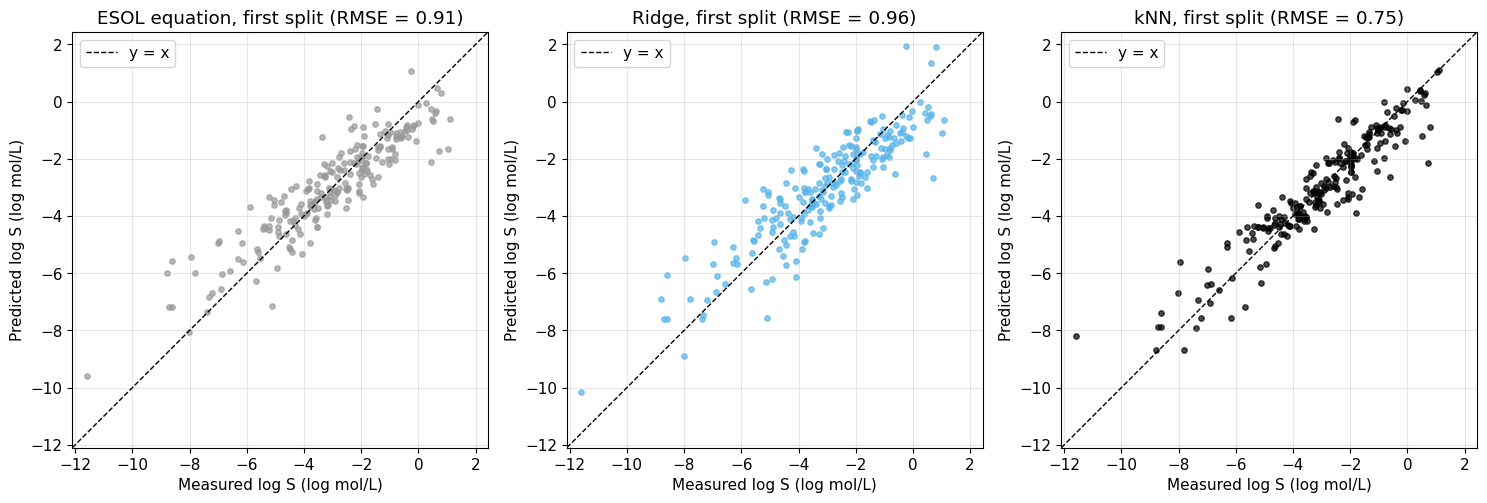

In [6]:
# Source: parity_plot() from the proposal (src/esol_evaluation.py), idea from Tutorial 4 (6.)
# Changes: all panels use the same axis limits so they can be compared
# grid.predict() uses the best model, refitted on the whole training set
y_pred_ridge = grid_ridge.predict(X_test)
y_pred_knn = grid_knn.predict(X_test)

all_values = np.concatenate([y_test, df_test[DELANEY], y_pred_ridge, y_pred_knn])
lims = [all_values.min() - 0.5, all_values.max() + 0.5]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
parity_plot(axes[0], y_test, df_test[DELANEY], 'ESOL equation, first split', lims,
            MODEL_COLOURS['ESOL equation (Delaney, 2004)'])
parity_plot(axes[1], y_test, y_pred_ridge, 'Ridge, first split', lims, MODEL_COLOURS['Ridge (8 descriptors)'])
parity_plot(axes[2], y_test, y_pred_knn, 'kNN, first split', lims, MODEL_COLOURS['kNN (8 descriptors)'])
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'baselines_parity_first_split.png'), dpi=300, bbox_inches='tight')
plt.show()

**Observations (first split)**

All baselines are much better than the mean predictor (RMSE 2.14). The 8 descriptors bring the RMSE down from 1.15 (logP only) to 0.96 for linear and ridge regression, which is close to Delaney's ESOL equation (0.91) on this split. kNN is the best baseline (RMSE 0.75, R² 0.88). Cross-validation chose 10 neighbours with distance weighting. In the parity plots, the ESOL equation and ridge pull their predictions towards the middle: the most insoluble molecules are predicted too soluble (above the y = x line on the left) and the most soluble ones not soluble enough (below the line on the right). kNN pulls its predictions towards the middle less, but it also has some large single errors.

### 3.1 What is left after the linear model?

If the 8-descriptor linear model still leaves a pattern in its residuals against a descriptor, that relationship is something a linear model can't capture, and a nonlinear model might (same analysis as proposal section 10.4b).

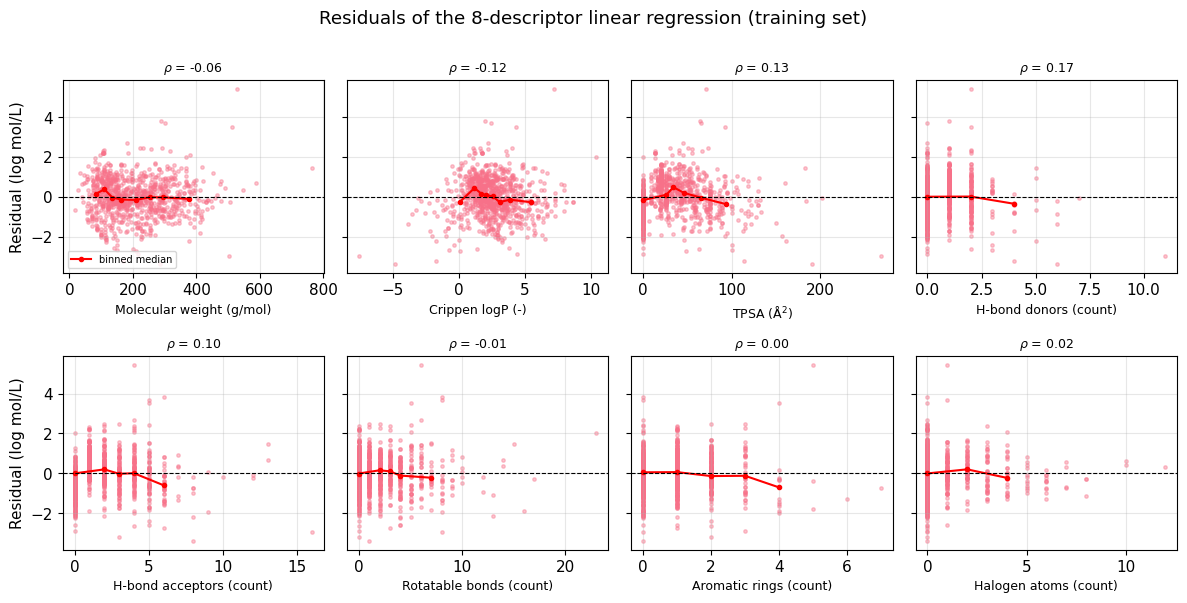

In [7]:
# Source: new (proposal section 10.4b). Residual = measured - predicted, the error that least squares makes small
#         (Tutorial 2, 5.). Scatter plots and Spearman correlation as in notebook 01 (sections 8.1 and 8.4)
# Changes (proposal): linear model residuals against each descriptor, with the binned median
lin_resid = y_train - linear_regressor.predict(X_train)

fig, axes = plt.subplots(2, 4, figsize=(12, 6), sharey=True)
for ax, f in zip(axes.ravel(), FEATURES):
    ax.scatter(df_train[f], lin_resid, s=6, alpha=0.4)
    # median residual in up to 8 bins (one bin per value for the small counts)
    if df_train[f].nunique() <= 8:
        bins = df_train[f].clip(upper=4) if f == 'AromRings' else df_train[f]   # few molecules with 5 or more rings
    else:
        bins = pd.qcut(df_train[f], 8, duplicates='drop')
    med = lin_resid.groupby(bins, observed=True).median()
    centers = df_train[f].groupby(bins, observed=True).median()
    ax.plot(centers, med, 'r-o', ms=3, lw=1.5, label='binned median')
    ax.axhline(0, color='k', lw=0.8, ls='--')
    rho = round(stats.spearmanr(df_train[f], lin_resid)[0], 2) + 0.0   # + 0.0 turns -0.0 into 0.0
    ax.set_xlabel(LABELS[f], fontsize=9)
    ax.set_title(f"$\\rho$ = {rho:.2f}", fontsize=9)
    ax.grid(True, alpha=0.3)
for ax in axes[:, 0]:
    ax.set_ylabel('Residual (log mol/L)')
axes[0, 0].legend(fontsize=7, loc='lower left')
fig.suptitle('Residuals of the 8-descriptor linear regression (training set)', y=1.0)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'baselines_linear_residuals.png'), dpi=300, bbox_inches='tight')
plt.show()

In [8]:
# Source: groups from 01_data_and_eda.ipynb (section 8). pandas groupby (not in the tutorials)
ring_group = df_train['AromRings'].clip(upper=4).astype(int).astype(str).replace('4', '4+')
tpsa_group = pd.cut(df_train['TPSA'], bins=[-1, 0, 20, 40, 60, 300], labels=['0', '0-20', '20-40', '40-60', '>60'])

print(f"Residual SD: {lin_resid.std():.2f}")
print(lin_resid.groupby(ring_group).agg(['count', 'mean', 'median']).round(2))
polar = df_train['LogP'] < -2
print(f"Very polar molecules (logP < -2): n = {polar.sum()}, mean residual = {lin_resid[polar].mean():.2f}, "
      f"most negative = {lin_resid[polar].min():.2f}")
print(lin_resid.groupby(tpsa_group, observed=True).median().round(2))

Residual SD: 0.97
           count  mean  median
AromRings                     
0            361 -0.07    0.06
1            298  0.12    0.07
2            179 -0.03   -0.13
3             36  0.03   -0.12
4+            18 -0.37   -0.70
Very polar molecules (logP < -2): n = 12, mean residual = -1.17, most negative = -3.38
TPSA
0       -0.48
0-20     0.43
20-40    0.57
40-60    0.17
>60     -0.16
Name: measured log solubility in mols per litre, dtype: float64


**Observations**

After the linear model none of the descriptors correlates strongly with the residuals any more (all |ρ| of 0.17 or less), as expected. Some shapes are still left that a straight line can't fit. Molecules with 4 or more aromatic rings are still over-predicted (median residual -0.70, mean -0.37), and so are the very polar molecules with logP < -2 (mean residual -1.17). The residual also goes up and then down with TPSA (median -0.48 for TPSA = 0, +0.57 for 20-40 Å², -0.16 above 60 Å²). These are the effects we found in the EDA. They could come from a curved relation that a nonlinear model can fit, or from something the 8 descriptors do not measure (for example crystal packing). `03_models.ipynb` tests the first with nonlinear models.

## 4. Baselines over 10 splits

One test set has only 223 molecules, so its error depends on which molecules happen to be in it. We repeat the split, the tuning and the test with seeds 1 to 10 and compare the models split by split, because in each split all models are tested on the same molecules (same as proposal section 10.5).

In [9]:
# Source: same stratified split as Tutorial 4 (1.1), logP fit from Tutorial 2 (5.), pipelines and
#         GridSearchCV from Tutorial 4 (9.1), regression_metrics() from Tutorial 4 (3.1)
# Changes: 10 seeds, as in the proposal. New in the final project: one function for both datasets, and it also keeps
#          the predictions

def run_baselines(data, split_seeds=range(1, 11)):
    """Fit and test every baseline on the same stratified splits. Returns metrics, predictions and kNN settings."""
    split_results = []      # one dictionary of metrics for each model and split
    all_predictions = []    # test-set predictions of each model and split
    knn_settings = []       # kNN settings chosen by cross-validation in each split

    for seed in split_seeds:
        df_tr, df_te = stratified_split(data, seed)
        X_tr, y_tr = df_tr[FEATURES], df_tr[TARGET]
        X_te, y_te = df_te[FEATURES], df_te[TARGET]
        predictions = {}

        # mean predictor
        dummyregressor_mean = DummyRegressor(strategy='mean').fit(X_tr, y_tr)
        predictions['Mean predictor'] = dummyregressor_mean.predict(X_te)

        # logP only, least squares fit on this training set
        X_logp = np.c_[np.ones(len(df_tr)), df_tr['LogP']]
        beta, _, _, _ = np.linalg.lstsq(X_logp, y_tr, rcond=None)
        predictions['logP only (least squares)'] = beta[0] + beta[1] * df_te['LogP']

        # ESOL equation (published predictions)
        predictions['ESOL equation (Delaney, 2004)'] = df_te[DELANEY]

        # same 4 terms as the ESOL equation, refitted with RDKit's Crippen logP on this training set
        esol_refit = LinearRegression().fit(df_tr[ESOL_TERMS], y_tr)
        predictions['ESOL refit (Crippen logP)'] = esol_refit.predict(df_te[ESOL_TERMS])

        # linear regression
        linear_regressor = make_linear_pipeline().fit(X_tr, y_tr)
        predictions['Linear regression (8 descriptors)'] = linear_regressor.predict(X_te)

        # ridge, alpha tuned again by 5-fold cross-validation on this training set
        grid_ridge = GridSearchCV(make_ridge_pipeline(), param_grid=ridge_param_grid, cv=5,
                                  scoring='neg_mean_absolute_error', n_jobs=N_JOBS)
        grid_ridge.fit(X_tr, y_tr)
        predictions['Ridge (8 descriptors)'] = grid_ridge.predict(X_te)

        # kNN, number of neighbours and weighting tuned by 5-fold cross-validation
        grid_knn = GridSearchCV(make_knn_pipeline(), param_grid=knn_param_grid, cv=5,
                                scoring='neg_mean_absolute_error', n_jobs=N_JOBS)
        grid_knn.fit(X_tr, y_tr)
        predictions['kNN (8 descriptors)'] = grid_knn.predict(X_te)
        knn_settings.append({'seed': seed, 'n_neighbors': grid_knn.best_params_['knn__n_neighbors'],
                             'weights': grid_knn.best_params_['knn__weights']})

        # metrics and predictions on this test set
        for model_name, y_pred in predictions.items():
            metrics = regression_metrics(y_te, y_pred)
            metrics['model'] = model_name
            metrics['seed'] = seed
            split_results.append(metrics)
            all_predictions.append(pd.DataFrame({
                'seed': seed, 'model': model_name, 'Compound ID': df_te['Compound ID'],
                'canonical_smiles': df_te['canonical_smiles'], 'y_true': y_te, 'y_pred': np.asarray(y_pred),
            }))

    return pd.DataFrame(split_results), pd.concat(all_predictions), pd.DataFrame(knn_settings)

In [10]:
# Source: the function above, run on the final dataset and on the proposal's dataset
split_df, predictions_df, knn_settings = run_baselines(df_clean)
model_order = list(split_df['model'].unique())

# test RMSE of each model in each split (one row per seed)
rmse_df = split_df.pivot(index='seed', columns='model', values='rmse')[model_order]
rmse_df.round(3)

model,Mean predictor,logP only (least squares),"ESOL equation (Delaney, 2004)",ESOL refit (Crippen logP),Linear regression (8 descriptors),Ridge (8 descriptors),kNN (8 descriptors)
seed,,,,,,,
1,2.141,1.149,0.915,1.005,0.961,0.962,0.749
2,2.134,1.203,0.939,1.041,0.984,0.986,0.841
3,2.193,1.261,0.882,0.995,0.952,0.952,0.776
4,2.223,1.108,0.920,1.008,0.958,0.958,0.850
5,2.211,1.211,0.968,1.078,1.014,1.018,0.807
6,2.154,1.217,0.972,1.112,1.059,1.059,0.767
7,2.058,1.163,0.937,1.047,0.999,0.999,0.809
8,2.055,1.256,0.963,1.127,1.081,1.081,0.821
9,2.062,1.318,0.911,1.070,1.001,0.999,0.803


In [11]:
# Source: groupby summary and paired comparison as in the proposal (section 10.5)
# mean and standard deviation over the 10 splits
split_summary = split_df.groupby('model')[['mae', 'rmse', 'r2']].agg(['mean', 'std']).loc[model_order]
print(split_summary.round(3))

# paired comparison: in each split both models are tested on the same molecules
for other in ['ESOL equation (Delaney, 2004)', 'ESOL refit (Crippen logP)', 'Ridge (8 descriptors)']:
    d = rmse_df['kNN (8 descriptors)'] - rmse_df[other]
    print(f"kNN - {other}: {d.mean():.3f} ± {d.std():.3f}, kNN lower in {(d < 0).sum()} of {len(d)} splits")
d = rmse_df['Ridge (8 descriptors)'] - rmse_df['ESOL equation (Delaney, 2004)']
print(f"Ridge - ESOL equation: {d.mean():.3f} ± {d.std():.3f}, ridge higher in {(d > 0).sum()} of {len(d)} splits")
print("(± is the SD over the 10 splits. The splits share molecules, so it is a summary, not a standard error)")

# how much of the ESOL equation's lead over the refit comes from fitting on the test molecules?
# the same 4 terms refitted on ALL 1,115 molecules (so on every test molecule too), then tested as above
esol_all = LinearRegression().fit(df_clean[ESOL_TERMS], df_clean[TARGET])
in_sample = []
for seed in range(1, 11):
    df_tr, df_te = stratified_split(df_clean, seed)
    in_sample.append(np.sqrt(((esol_all.predict(df_te[ESOL_TERMS]) - df_te[TARGET]) ** 2).mean()))
print(f"ESOL refit on all molecules (in-sample), mean test RMSE: {np.mean(in_sample):.3f}")

# kNN settings chosen by cross-validation
print(knn_settings.to_string(index=False))

# save the tables for the paper and the later notebooks
split_df.to_csv(os.path.join(TABLE_DIR, 'baselines_per_split.csv'), index=False)
split_summary.round(4).to_csv(os.path.join(TABLE_DIR, 'baselines_summary.csv'))
predictions_df.to_csv(os.path.join(TABLE_DIR, 'baselines_test_predictions.csv'))
knn_settings.to_csv(os.path.join(TABLE_DIR, 'baselines_knn_settings.csv'), index=False)

                                     mae          rmse            r2       
                                    mean    std   mean    std   mean    std
model                                                                      
Mean predictor                     1.680  0.046  2.132  0.064 -0.001  0.001
logP only (least squares)          0.932  0.026  1.205  0.062  0.678  0.044
ESOL equation (Delaney, 2004)      0.713  0.023  0.929  0.033  0.810  0.017
ESOL refit (Crippen logP)          0.810  0.030  1.052  0.045  0.755  0.030
Linear regression (8 descriptors)  0.779  0.029  1.003  0.043  0.777  0.028
Ridge (8 descriptors)              0.779  0.029  1.003  0.043  0.777  0.028
kNN (8 descriptors)                0.568  0.017  0.803  0.032  0.858  0.014
kNN - ESOL equation (Delaney, 2004): -0.126 ± 0.043, kNN lower in 10 of 10 splits
kNN - ESOL refit (Crippen logP): -0.249 ± 0.053, kNN lower in 10 of 10 splits
kNN - Ridge (8 descriptors): -0.200 ± 0.053, kNN lower in 10 of 10 splits
Ridge 

**Observations (10 splits)**

- Over the 10 splits, the test RMSE of each model moves by 0.03 to 0.06 log units (SD), as much as some of the gaps between models. So we compare the models split by split, on the same test molecules.
- The 10 test sets share molecules (each molecule is in about 2 of them), so the splits are not independent. The SD and the "10 of 10" counts are summaries of the splits, not a statistical test.
- kNN is the best baseline: RMSE 0.80 ± 0.03, R² 0.86. It beats the ESOL equation, the ESOL refit and ridge in 10 of 10 splits (by 0.13, 0.25 and 0.20 log units on average).
- Linear and ridge regression give the same error (RMSE 1.00), because cross-validation chose a small alpha (3.16 on the first split) for 892 training molecules and 8 descriptors, so ridge hardly shrinks the coefficients. They are worse than the ESOL equation in 10 of 10 splits, but better than the ESOL refit (1.05).
- The ESOL equation (0.93) beats the refit (1.05) by 0.12. Fitting on the test molecules explains only about 0.01 of this: the same 4 terms refitted on all 1,115 molecules (in-sample) still give 1.04. Most of the gap must come from what Delaney's equation has and the refit does not: his commercial logP and his larger fitting set. Delaney's set contains our molecules, so we treat the ESOL equation as partly in-sample. The refit with our Crippen logP on each training set is the fair linear baseline.
- Cross-validation chose distance weighting for kNN in all 10 splits (5 to 10 neighbours).
- The benchmark for the research question is kNN (RMSE 0.80), compared split by split.

### 4.1 Before and after merging the cis/trans pairs

To show the effect of the improved duplicate merging, we run exactly the same baselines on the proposal's dataset (1,117 molecules). This reproduces the proposal's table.

In [12]:
# Source: new (final project). Same baselines on the proposal's dataset (1,117 molecules)
split_df_proposal, _, _ = run_baselines(df_proposal)

# mean and SD of the test RMSE over the 10 splits, for each model and both datasets
rows = []
for model_name in model_order:
    rmse_proposal = split_df_proposal[split_df_proposal['model'] == model_name]['rmse']
    rmse_final = split_df[split_df['model'] == model_name]['rmse']
    rows.append({
        'model': model_name,
        'RMSE, proposal (1,117)': rmse_proposal.mean(),
        'SD, proposal': rmse_proposal.std(),
        'RMSE, final (1,115)': rmse_final.mean(),
        'SD, final': rmse_final.std(),
    })
before_after = pd.DataFrame(rows).set_index('model').round(3)

# the change is calculated from the rounded values, so the table adds up
before_after['change'] = (before_after['RMSE, final (1,115)'] - before_after['RMSE, proposal (1,117)']).round(3)
before_after.to_csv(os.path.join(TABLE_DIR, 'baselines_before_after_merge.csv'))
before_after

,"RMSE, proposal (1,117)","SD, proposal","RMSE, final (1,115)","SD, final",change
model,,,,,
Mean predictor,2.099,0.081,2.132,0.064,0.033
logP only (least squares),1.179,0.069,1.205,0.062,0.026
"ESOL equation (Delaney, 2004)",0.909,0.043,0.929,0.033,0.020
ESOL refit (Crippen logP),1.028,0.061,1.052,0.045,0.024
Linear regression (8 descriptors),0.976,0.060,1.003,0.043,0.027
Ridge (8 descriptors),0.976,0.060,1.003,0.043,0.027
kNN (8 descriptors),0.767,0.050,0.803,0.032,0.036


In [13]:
# Source: new (final project). Test molecules that are the same before and after the merge
# Changes: the 2 merged pairs are compared without their cis/trans marks
def strip_stereo(smiles):
    """Remove the cis/trans bond marks (/ and \\) from a SMILES, so the old and new SMILES match."""
    # this is enough here because no ESOL SMILES has chiral (@) marks
    return smiles.replace('/', '').replace('\\', '')

for seed in range(1, 11):
    test_old = set(stratified_split(df_proposal, seed)[1]['canonical_smiles'].map(strip_stereo))
    test_new = set(stratified_split(df_clean, seed)[1]['canonical_smiles'])
    print(f"seed {seed:2d}: {len(test_old & test_new)} of {len(test_new)} test molecules are the same")

# kNN against the ESOL equation, split by split, in both versions
rmse_old = split_df_proposal.pivot(index='seed', columns='model', values='rmse')
d_old = rmse_old['kNN (8 descriptors)'] - rmse_old['ESOL equation (Delaney, 2004)']
d_new = rmse_df['kNN (8 descriptors)'] - rmse_df['ESOL equation (Delaney, 2004)']
print(f"kNN - ESOL equation, proposal: {d_old.mean():.3f} (kNN lower in {(d_old < 0).sum()} of 10 splits)")
print(f"kNN - ESOL equation, final:    {d_new.mean():.3f} (kNN lower in {(d_new < 0).sum()} of 10 splits)")

seed  1: 108 of 223 test molecules are the same
seed  2: 104 of 223 test molecules are the same
seed  3: 106 of 223 test molecules are the same
seed  4: 109 of 223 test molecules are the same
seed  5: 112 of 223 test molecules are the same
seed  6: 107 of 223 test molecules are the same
seed  7: 117 of 223 test molecules are the same
seed  8: 117 of 223 test molecules are the same
seed  9: 111 of 223 test molecules are the same
seed 10: 110 of 223 test molecules are the same
kNN - ESOL equation, proposal: -0.141 (kNN lower in 10 of 10 splits)
kNN - ESOL equation, final:    -0.126 (kNN lower in 10 of 10 splits)


**Observations (before/after the merge)**

Merging the 2 cis/trans pairs (1,117 to 1,115 molecules) raises the mean test RMSE of every model by 0.02 to 0.04 log units, including the ESOL equation, whose predictions are fixed, and the mean predictor, which only predicts the training mean. The reason is that removing 2 rows changes the random splits: only about half of the 223 test molecules (104 to 117) are the same as in the proposal's splits, so these are new test sets. The comparisons inside each split hardly change: kNN beats the ESOL equation by 0.126 log units on average (0.141 in the proposal), in 10 of 10 splits in both versions. When the test sets change, the RMSE of each model moves by a few hundredths, but the ranking stays the same. This supports comparing the models split by split. With the proposal's dataset this code reproduces the proposal's table (mean predictor 2.10, logP only 1.18, ESOL equation 0.91, ESOL refit 1.03, linear and ridge 0.98, kNN 0.77).

## 5. Why kNN does well: molecules with a descriptor "twin"

In `01_data_and_eda.ipynb` (7.3) we found that 23% of the training molecules share all 8 descriptors with another molecule. Cross-validation chose distance weighting for kNN, so a test molecule with exactly the same descriptors as one or more training molecules (distance 0) gets their log S (the mean, if there are several). Here we split the error of kNN, the ESOL equation, the ESOL refit and ridge into test molecules with and without such a twin in the training set, so all four models are compared on the same molecules. This is the degeneracy problem of Lecture 2 (slide 18): different molecules with the same feature vector.

In [14]:
# Source: new (final project). Test errors with and without a descriptor twin in the training set
TWIN_MODELS = ['kNN (8 descriptors)', 'ESOL equation (Delaney, 2004)', 'ESOL refit (Crippen logP)',
               'Ridge (8 descriptors)']
twin_rows = []

for seed in range(1, 11):
    df_tr, df_te = stratified_split(df_clean, seed)

    # training descriptors, rounded to 6 decimals to remove tiny float differences (notebook 01, section 7.3)
    train_descriptors = set()
    for row in df_tr[FEATURES].round(6).values:
        train_descriptors.add(tuple(row))

    # True for a test molecule whose descriptors are also in the training set
    has_twin = []
    for row in df_te[FEATURES].round(6).values:
        has_twin.append(tuple(row) in train_descriptors)
    has_twin = pd.Series(has_twin, index=df_te.index)

    for model_name in TWIN_MODELS:
        pred = predictions_df[(predictions_df['seed'] == seed) & (predictions_df['model'] == model_name)]
        # the predictions keep the index of df_te, so has_twin lines up with them
        errors = pred['y_true'] - pred['y_pred']
        twin_rows.append({
            'seed': seed,
            'model': model_name,
            'n_twins': has_twin.sum(),
            'rmse_all': np.sqrt((errors ** 2).mean()),
            'rmse_twins': np.sqrt((errors[has_twin] ** 2).mean()),
            'rmse_no_twin': np.sqrt((errors[~has_twin] ** 2).mean()),
        })

twin_df = pd.DataFrame(twin_rows)
twin_df.to_csv(os.path.join(TABLE_DIR, 'baselines_twins.csv'), index=False)

# mean over the 10 splits
print(f"Test molecules with a twin in the training set: {twin_df['n_twins'].mean():.1f} of {len(df_te)} on average")
print(twin_df.groupby('model')[['rmse_all', 'rmse_twins', 'rmse_no_twin']].mean().loc[TWIN_MODELS].round(3))

# paired comparison on the molecules without a twin
no_twin = twin_df.pivot(index='seed', columns='model', values='rmse_no_twin')
for other in ['ESOL equation (Delaney, 2004)', 'ESOL refit (Crippen logP)', 'Ridge (8 descriptors)']:
    d = no_twin['kNN (8 descriptors)'] - no_twin[other]
    print(f"Without a twin, kNN - {other}: {d.mean():.3f} ± {d.std():.3f}, kNN lower in {(d < 0).sum()} of 10 splits")

Test molecules with a twin in the training set: 49.7 of 223 on average
                               rmse_all  rmse_twins  rmse_no_twin
model                                                            
kNN (8 descriptors)               0.803       0.468         0.876
ESOL equation (Delaney, 2004)     0.929       1.061         0.884
ESOL refit (Crippen logP)         1.052       1.081         1.040
Ridge (8 descriptors)             1.003       0.994         1.003
Without a twin, kNN - ESOL equation (Delaney, 2004): -0.008 ± 0.059, kNN lower in 6 of 10 splits
Without a twin, kNN - ESOL refit (Crippen logP): -0.164 ± 0.079, kNN lower in 10 of 10 splits
Without a twin, kNN - Ridge (8 descriptors): -0.127 ± 0.075, kNN lower in 9 of 10 splits


In [15]:
# Source: new (final project). Share of kNN's gain over each linear model that comes from the twins
# gain of a molecule = other model's squared error - kNN's squared error, added up over all 10 splits
OTHER_MODELS = ['ESOL equation (Delaney, 2004)', 'ESOL refit (Crippen logP)', 'Ridge (8 descriptors)']
gain_rows = []
for seed in range(1, 11):
    df_tr, df_te = stratified_split(df_clean, seed)
    # the same twin check as in the cell above
    train_descriptors = set()
    for row in df_tr[FEATURES].round(6).values:
        train_descriptors.add(tuple(row))
    has_twin = []
    for row in df_te[FEATURES].round(6).values:
        has_twin.append(tuple(row) in train_descriptors)
    has_twin = pd.Series(has_twin, index=df_te.index)

    # squared error of kNN on each test molecule, then the gain of kNN over each other model
    knn = predictions_df[(predictions_df['seed'] == seed) & (predictions_df['model'] == 'kNN (8 descriptors)')]
    knn_squared = (knn['y_true'] - knn['y_pred']) ** 2
    for other in OTHER_MODELS:
        pred = predictions_df[(predictions_df['seed'] == seed) & (predictions_df['model'] == other)]
        gain = (pred['y_true'] - pred['y_pred']) ** 2 - knn_squared
        gain_rows.append({'other': other, 'seed': seed, 'gain_twins': gain[has_twin].sum(),
                          'gain_no_twin': gain[~has_twin].sum(), 'n_twins': has_twin.sum(), 'n_test': len(df_te)})
gain_df = pd.DataFrame(gain_rows)

# the twins are the same in every comparison, so we count them in the first one
first = gain_df[gain_df['other'] == OTHER_MODELS[0]]
twin_share = first['n_twins'].sum() / first['n_test'].sum()
print(f"Twins are {twin_share:.0%} of the test molecules (all 10 splits together)")

# ratio of sums: total gain on the twins / total gain on all test molecules
for other in OTHER_MODELS:
    rows = gain_df[gain_df['other'] == other]
    gain_twins = rows['gain_twins'].sum()
    gain_no_twin = rows['gain_no_twin'].sum()
    share = gain_twins / (gain_twins + gain_no_twin)
    # the same share in each split (above 100% if kNN is worse on the molecules without a twin)
    per_split = rows['gain_twins'] / (rows['gain_twins'] + rows['gain_no_twin'])
    print(f"kNN against {other}: {share:.0%} of kNN's reduction in squared error comes from the twins "
          f"(per split {per_split.min():.0%} to {per_split.max():.0%})")

Twins are 22% of the test molecules (all 10 splits together)
kNN against ESOL equation (Delaney, 2004): 95% of kNN's reduction in squared error comes from the twins (per split 47% to 201%)
kNN against ESOL refit (Crippen logP): 47% of kNN's reduction in squared error comes from the twins (per split 19% to 93%)
kNN against Ridge (8 descriptors): 48% of kNN's reduction in squared error comes from the twins (per split 21% to 119%)


**Observations**

- About 50 of the 223 test molecules (22%) have a "twin" in the training set with the same 8 descriptors.
- kNN predicts these molecules very well (RMSE 0.47) because it gives them the log S of their twin, or the mean when there are several twins. The linear models do not get this benefit. The ESOL equation has an RMSE of 1.06 on them and ridge 0.99.
- On the molecules without a twin, kNN (0.88) and the ESOL equation (0.88) are about equal. kNN is lower in only 6 of 10 splits. But the ESOL equation was fitted by Delaney on these same molecules, so the comparison is not fair here.
- On the molecules without a twin, kNN is still better than the fair linear baselines. Its RMSE is lower than the ESOL refit (1.04) in 10 of 10 splits and lower than ridge (1.00) in 9 of 10.
- The twins are 22% of the test molecules, but 95% of kNN's reduction in squared error against the ESOL equation comes from them, compared with 47% for the ESOL refit and 48% for ridge (all 10 splits added up).
- We decided to say "almost all" only for a share above 90%. We set this rule before the final run, but after we had already run a first draft of this check. The total share against the ESOL equation (95%) is above 90%, but in single splits it goes from 47% to 201% (above 100% where kNN is worse than the ESOL equation on the molecules without a twin). It is not a stable number, so we only say that most of kNN's advantage over the ESOL equation comes from the twins. The twins are also harder for the ESOL equation (1.06 against 0.88 without a twin), so part of this share comes from that.
- Against the fair linear baselines only about half of kNN's advantage comes from the twins, and kNN is still better on the molecules without a twin. The scaffold split in `04_scaffold_split_and_uncertainty.ipynb` tests the models on molecules whose scaffold is not in the training set at all.

### 5.1 Which molecules make the ESOL equation worse on the twins?

The ESOL equation has a higher RMSE on the test molecules with a twin (1.06) than on the others (0.88), while ridge does not (0.99 and 1.00). The ESOL equation's predictions are the same in every split, so the gap can only come from which molecules happen to be twins. Here we look at which molecules are twins. We use the families of `05_interpretation.ipynb` (section 8): steroids, PCBs, large PAHs, sugars and polyols, and the other molecules. They are defined by rules on the structure (in `src/esol_data.py`) before any error was computed. We pool the test predictions of all 10 splits, so a molecule counts once for every split in which it is a test molecule, and the RMSE is taken over the pooled predictions (not the mean of the 10 split RMSEs of section 5). We also give the RMSE per unique molecule (each molecule's errors averaged first), and the mean measured log S of the twins and the other test molecules, because the ESOL equation may simply do worse on very insoluble molecules.

We decided before running this check how to read it. The pooled RMSE decides, and the RMSE per unique molecule is shown for comparison. We say that the PCBs explain most of the ESOL equation's gap only if, with the PCBs left out of both groups, its RMSE on the twins is at most 0.05 above its RMSE on the molecules without a twin. We do not interpret a family with fewer than 10 unique twin molecules. (A first version of this cell left the PCBs out of the twins only. We changed this after we checked the code, and by then we had already seen its output. Both versions give the same answer.)

In [16]:
# Source: new (final project). The twin errors of section 5, split by family. pandas groupby (not in the tutorials)
#         The family rules are those of notebook 05 (section 8), kept in src/esol_data.py


def pooled_and_unique_rmse(rows):
    """RMSE over all pooled predictions, and over the unique molecules (squared errors averaged per molecule)."""
    per_molecule = rows['squared_error'].groupby(rows.index).mean()
    return np.sqrt(rows['squared_error'].mean()), np.sqrt(per_molecule.mean())


scaffolds = murcko_scaffolds(df_clean)
families = molecule_families(df_clean, scaffolds)

FAMILY_MODELS = ['ESOL equation (Delaney, 2004)', 'Ridge (8 descriptors)', 'kNN (8 descriptors)']
family_tables = []
for seed in range(1, 11):
    df_tr, df_te = stratified_split(df_clean, seed)
    # the same twin check as in section 5
    train_descriptors = set()
    for row in df_tr[FEATURES].round(6).values:
        train_descriptors.add(tuple(row))
    has_twin = []
    for row in df_te[FEATURES].round(6).values:
        has_twin.append(tuple(row) in train_descriptors)
    has_twin = pd.Series(has_twin, index=df_te.index)

    for model_name in FAMILY_MODELS:
        pred = predictions_df[(predictions_df['seed'] == seed) & (predictions_df['model'] == model_name)]
        # one row per test molecule: its family, whether it has a twin, its log S and its squared error
        family_tables.append(pd.DataFrame({'seed': seed, 'model': model_name,
                                           'family': families.loc[pred.index],
                                           'twin': has_twin.loc[pred.index],
                                           'log_s': pred['y_true'],
                                           'squared_error': (pred['y_true'] - pred['y_pred']) ** 2}))
family_errors = pd.concat(family_tables)

# number of test predictions and RMSE for each model, family and twin / no twin (all 10 splits pooled)
summary = family_errors.groupby(['model', 'family', 'twin'])['squared_error'].agg(['count', 'mean'])
summary['rmse'] = np.sqrt(summary['mean'])
summary = summary.drop(columns='mean').reset_index()
summary.round(3).to_csv(os.path.join(TABLE_DIR, 'baselines_twins_by_family.csv'), index=False)

# the twins per family (the same for every model): test predictions and unique molecules
esol = family_errors[family_errors['model'] == FAMILY_MODELS[0]]
twins = esol[esol['twin']]
print("Twins per family (10 splits pooled): test predictions, unique molecules")
for family in FAMILY_ORDER:
    in_family = twins[twins['family'] == family]
    n_unique = in_family.index.nunique()
    # families with fewer than 10 unique twin molecules are not interpreted (rule above)
    if n_unique < 10:
        note = '(fewer than 10, not interpreted)'
    else:
        note = ''
    print(f"   {family:16s} {len(in_family):4d} {n_unique:4d} {note}")
print(f"Mean measured log S: twins {twins['log_s'].mean():.2f}, molecules without a twin "
      f"{esol.loc[~esol['twin'], 'log_s'].mean():.2f}")

# RMSE and number of test predictions on the twins and on the other molecules, per model and family
table = summary.pivot_table(index=['model', 'family'], columns='twin', values=['count', 'rmse'])
table.columns = ['n_no_twin', 'n_twin', 'rmse_no_twin', 'rmse_twin']   # count before rmse, twin False before True
table[['n_no_twin', 'n_twin']] = table[['n_no_twin', 'n_twin']].astype('Int64')   # whole numbers, empty if none
for model_name in FAMILY_MODELS:
    print(f"\n{model_name}, number of test predictions and RMSE without and with a twin in the training set:")
    print(table.loc[model_name].reindex(FAMILY_ORDER).round(3).to_string())

# the rule set before the run: the ESOL equation without the PCBs, in both groups
not_pcb = esol['family'] != 'PCB'
groups = [('all molecules', esol[esol['twin']], esol[~esol['twin']]),
          ('without the PCBs', esol[esol['twin'] & not_pcb], esol[~esol['twin'] & not_pcb])]
gaps = {}
for label, rows_twin, rows_no_twin in groups:
    twin_pooled, twin_unique = pooled_and_unique_rmse(rows_twin)
    other_pooled, other_unique = pooled_and_unique_rmse(rows_no_twin)
    gaps[label] = twin_pooled - other_pooled
    print(f"\nESOL equation, {label}: twins {twin_pooled:.3f} (per unique molecule {twin_unique:.3f}), "
          f"no twin {other_pooled:.3f} ({other_unique:.3f}), gap {gaps[label]:+.3f}")
print(f"Rule: the PCBs explain most of the gap if the gap without the PCBs is at most +0.05: "
      f"{gaps['without the PCBs'] <= 0.05}")

Twins per family (10 splits pooled): test predictions, unique molecules
   steroid             0    0 (fewer than 10, not interpreted)
   PCB                65   30 
   large PAH          22   13 
   sugar or polyol     0    0 (fewer than 10, not interpreted)
   other             410  198 
Mean measured log S: twins -3.36, molecules without a twin -2.98

ESOL equation (Delaney, 2004), number of test predictions and RMSE without and with a twin in the training set:
                 n_no_twin  n_twin  rmse_no_twin  rmse_twin
family                                                     
steroid                 86    <NA>         0.825        NaN
PCB                      3      65         2.011      0.828
large PAH               16      22         2.104      2.093
sugar or polyol         31    <NA>         0.589        NaN
other                 1597     410         0.868      1.023

Ridge (8 descriptors), number of test predictions and RMSE without and with a twin in the training set:
      

**Observations**

- Most twins are in the "other" family (198 unique molecules, 410 test predictions). There are also 30 PCBs (65 predictions) and 13 large PAHs (22 predictions). No steroid and no sugar or polyol has a twin, so we do not interpret these two families.
- The PCBs do not explain most of the ESOL equation's gap. It predicts the PCB twins better than the twins of the "other" family (RMSE 0.828 against 1.023), and with the PCBs left out the gap gets bigger (+0.222 instead of +0.186). This is above our limit of +0.05.
- The gap does not come from one family. In the "other" family alone, the ESOL equation has an RMSE of 1.023 on the twins and 0.868 on the molecules without a twin. The large PAHs are predicted badly with or without a twin (2.093 and 2.104).
- The RMSE per unique molecule gives the same picture (1.055 on the twins against 0.894).
- The twins are a little less soluble on average (mean log S -3.36 against -2.98). This could explain part of the gap, but we did not test it.
- Ridge, which is fitted on each training set, does not show this gap in the "other" family (1.011 on the twins and 1.004 without). So not every linear model shows this gap.

## Next notebook

`03_models.ipynb` trains the proposed models (kernel ridge, random forest and XGBoost) on the same 10 splits and compares them with these baselines (`results/tables/baselines_per_split.csv`).